### 이진 분류

In [150]:
import torch
import matplotlib.pyplot as plt

##### Step 1. 데이터 생성

In [151]:
N = 20

random0 = torch.randn(int(N/2), 1)
random5 = torch.randn(int(N/2), 1)+5

# data
class1_data = torch.hstack([random0, random5])  # 10행 2열
class2_data = torch.hstack([random5, random0])

# label
class1_label = torch.ones(int(N/2), 1)  # 10행 1열
class2_label = torch.zeros(int(N/2), 1)

x = torch.vstack([class1_data, class2_data])    # 20행 2열
y = torch.vstack([class1_label, class2_label])  # 20행 1열
print(x)
print(y)

tensor([[ 0.1402,  4.9803],
        [ 2.1951,  5.5619],
        [ 0.5091,  4.1760],
        [-0.4028,  5.1983],
        [ 1.5890,  4.8352],
        [ 1.2711,  6.5817],
        [ 0.3560,  5.0965],
        [ 1.3677,  4.7655],
        [-1.4815,  3.4212],
        [-0.3161,  5.3427],
        [ 4.9803,  0.1402],
        [ 5.5619,  2.1951],
        [ 4.1760,  0.5091],
        [ 5.1983, -0.4028],
        [ 4.8352,  1.5890],
        [ 6.5817,  1.2711],
        [ 5.0965,  0.3560],
        [ 4.7655,  1.3677],
        [ 3.4212, -1.4815],
        [ 5.3427, -0.3161]])
tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])


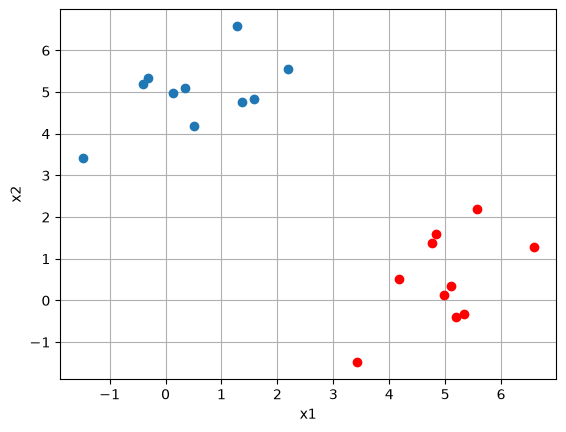

In [152]:
plt.plot(class1_data[:,0], class1_data[:,1], 'o')
plt.plot(class2_data[:,0], class2_data[:,1], 'ro')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid()

#### Step2. 모델 만들기

In [153]:
from torch import nn

class MLP(nn.Module) :
    def __init__(self) :
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(2, 100),
                                    nn.Sigmoid(),
                                    nn.Linear(100, 1),
                                    nn.Sigmoid()
                                    )

        # self.linear = nn.Sequential(nn.Linear(2, 1),
        #                             nn.Sigmoid(),
        #                             )

        # self.linear = nn.Sequential(nn.Linear(2, 100),
        #                             nn.Sigmoid(),
        #                             nn.Linear(100, 100),
        #                             nn.Sigmoid(),
        #                             nn.Linear(100, 100),
        #                             nn.Sigmoid(),
        #                             nn.Linear(100, 1),
        #                             nn.Sigmoid(),
        #                             )
    def forward(self, x):
        x = self.linear(x)
        return x

In [154]:
model = MLP()
# print(model)

b = model(torch.randn(5,2))
print(b.shape)
print(b)

torch.Size([5, 1])
tensor([[0.4700],
        [0.4534],
        [0.4579],
        [0.4782],
        [0.4827]], grad_fn=<SigmoidBackward0>)


#### Step 3. 모델 학습시키기

In [155]:
from torch import optim

LR = 1e-1
EPOCH = 100

optimizer = optim.SGD(model.parameters(), lr=LR)
# optimizer = optim.Adam(model.parameters(), lr=LR)
criterion = nn.BCELoss()

loss_history = []

model.train()   # train mode로 전환
for ep in range(EPOCH) :
    # 예측값
    y_hat = model(x)

    # loss구하기
    loss = criterion(y_hat, y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    loss_history += [loss.item()]
    # print
    # 
    # print(f'Epoch : {ep+1}, train loss : {loss.item():.4f}')
    # print('-' * 20)

Text(0, 0.5, 'Loss')

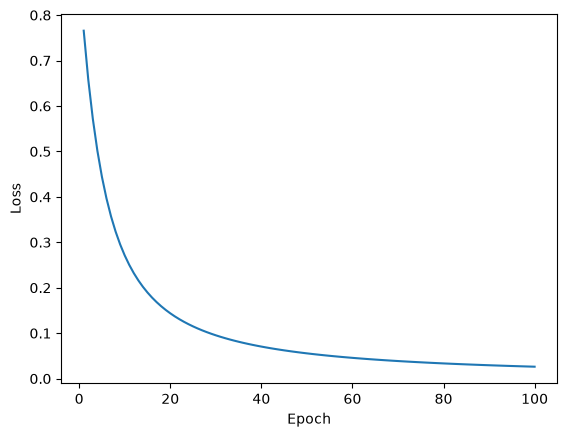

In [156]:
plt.plot(range(1,EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')